<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал,
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [ ]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

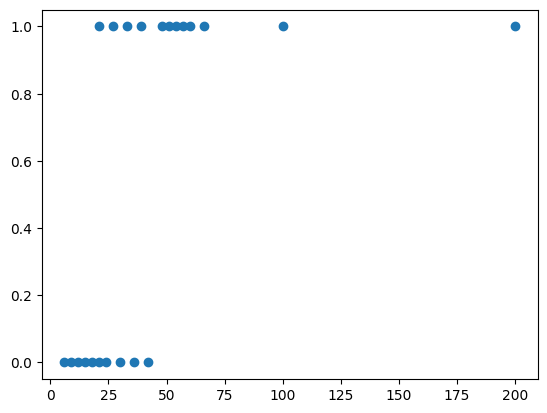

In [ ]:
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого.
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [ ]:
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


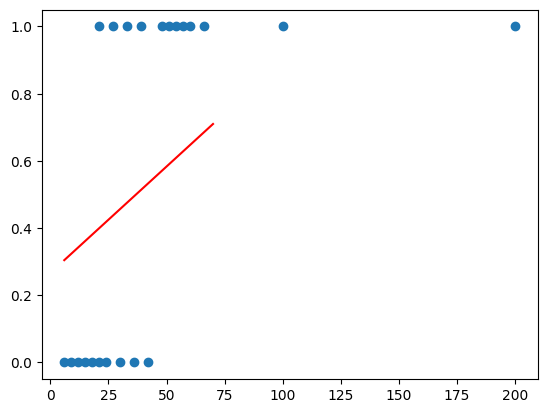

In [ ]:
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function),
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том,
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE,
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [ ]:
#Реализуем цикл градиентного спуска
class LogisticRegressionGD(object):
    def __init__(self):
        self.a = np.zeros(2).reshape(1, 2)

    def sigmoid(self, x):
        return 1/(1 + np.exp(-x @ self.a))

    def predict(self, x):
        return self.sigmoid(x)

    def coefs(self):
        return self.a

    def LogLikelihood(self, x, Y):
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()

    def accuracy(self, x, Y):
        return ((self.predict(x) > 0.5)==Y).mean()

    def fit(self, x, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL"):
        self.a = np.zeros (x.shape[1]).reshape(x.shape[1],1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                dT_a = x.T @(Y - self.predict(x)) / x.shape[0]
                self.a += alpha*dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                #display(new_error)
                dT_a = -x.T @(Y - self.predict(x)) / x.shape[0]
                self.a -= alpha*dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            #if new_error < epsylon:
            #    break
        return steps, errors

In [ ]:
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [ ]:
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE")

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL")

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 25.19630265235901 сек.'

'Время обучения: 22.483882904052734 сек.'

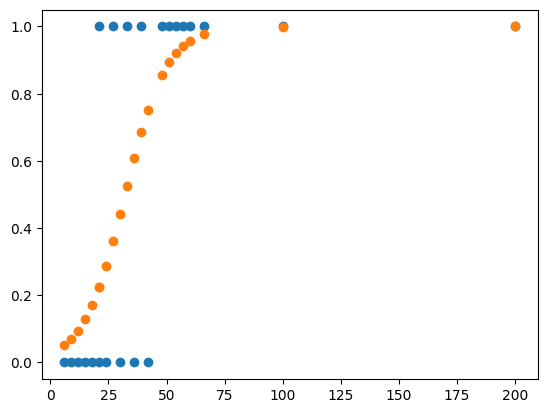

In [ ]:
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [ ]:
display(regr_CE.coefs())
#display(x_)

,0
0,-3.598933
1,0.112155


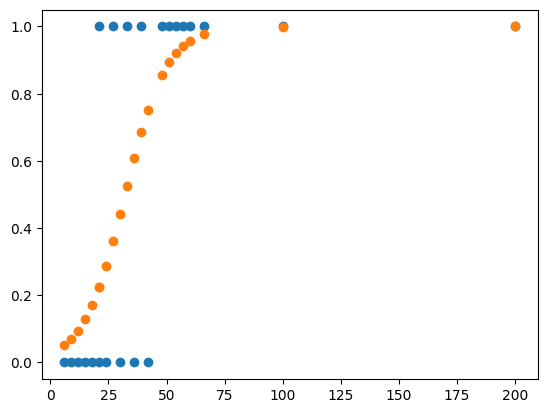

In [ ]:
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [ ]:
display(regr_LL.coefs())
#display(x_)

,0
0,-3.598933
1,0.112155


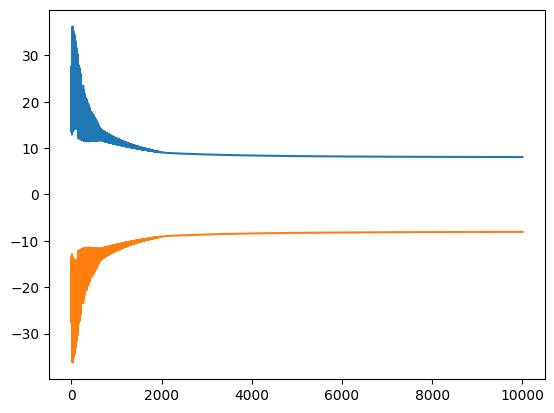

In [ ]:
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [ ]:
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);
variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);
variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);
variable_4 - идентификатор года выпуска транспортного средства;
variable_5 - идентификатор страны - производителя транспортного средства;
variable_6 - мощность двигателя в лошадиных силах;
variable_7 - объем двигателя в куб. см;
variable_8 - идентификатор стороны расположения руля (левый или правый);
variable_9 - пробег транспортного средства, покрываемый гарантией производителя;
variable_10 - индикатор действия гарантии на транспортное средство;
variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;
variable_12 - возраст транспортного средства (в мес.);
variable_13 - возраст водителя с максимальным стажем;
variable_14 - коэффициент возраст-стаж;
variable_15 - коэффициент краткосрочности;
variable_16 - коэффициент мощности;
variable_17 - коэффициент "мультидрайв";
variable_18 - территориальный коэффициент;
variable_19 - коэффициент "КНДР";
variable_20 - идентификатор канала продаж;
variable_21 - марка транспортного средства;
variable_22 - модель транспортного средства;
variable_23 - индикатор отечественных транспортных средств;
variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";
variable_25 - индикатор пролонгации;
variable_26 - индикатор совпадения собственника транспортного средства и водителя;
variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";
variable_28 - тип транспортного средства;
target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

# Бинарная логистическая регрессия для классификации страховых договоров

## Цель работы

Необходимо построить модель бинарной классификации, которая будет
предсказывать, является ли страховой договор рисковым.

Целевая переменная `target` принимает два значения:

- `0` — договор не является рисковым;
- `1` — договор является рисковым.

В работе будут реализованы два метода обучения логистической регрессии:

1. метод градиентного подъёма для максимизации логарифмического правдоподобия;
2. метод градиентного спуска для минимизации функции бинарной кросс-энтропии.

Для сравнения методов будут рассчитаны:

- время обучения;
- accuracy;
- precision;
- recall;
- F1-score;
- матрица ошибок.

Так как отдельного тестового файла нет, файл `insclass_train.csv`
будет разделён на обучающую и тестовую выборки.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import time
from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from IPython.display import display

# Отображение всех столбцов таблицы
pd.set_option("display.max_columns", None)

# Формат отображения чисел
pd.set_option("display.float_format", "{:.4f}".format)

## Загрузка данных

В обучающем наборе находятся 151 406 страховых договоров и 28 признаков.

Последний столбец `target` является целевой переменной.

In [ ]:
train_path = Path("insclass_train.csv")

if not train_path.exists():
    raise FileNotFoundError(
        "Файл insclass_train.csv не найден. "
        "Положите его в папку с Jupyter Notebook."
    )

df = pd.read_csv(train_path)

print("Размер датасета:", df.shape)
display(df.head())
display(df.info())

Размер датасета: (151406, 29)


,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,variable_9,variable_10,variable_11,variable_12,variable_13,variable_14,variable_15,variable_16,variable_17,variable_18,variable_19,variable_20,variable_21,variable_22,variable_23,variable_24,variable_25,variable_26,variable_27,variable_28,target
0,w200,0,0,14,q2,98.0000,NaN,0.0000,NaN,0,0,166.2670,49.0417,80.9852,NaN,98.6481,80.9852,80.9852,127.1132,C,j2,h45,0,0.0000,0,1,19.3235,t1,0
1,w160,0,0,7,q11,106.0000,NaN,0.0000,NaN,0,0,80.3386,82.7569,80.9852,NaN,118.1166,80.9852,38.7043,148.9057,C,j33,h234,0,1.0000,0,1,41.1779,t1,0
2,w200,0,0,4,q3,123.0000,NaN,0.0000,NaN,0,0,38.5199,35.8423,80.9852,NaN,162.5140,80.9852,273.4134,154.2449,B,j12,h28,0,0.0000,0,1,3.6144,t1,0
3,w200,0,0,9,q3,102.0000,NaN,0.0000,NaN,0,0,109.8458,70.5496,80.9852,NaN,118.1166,80.9852,80.9852,131.0678,C,j12,h64,0,1.0000,0,0,49.0417,t1,0
4,w200,0,0,18,q20,117.0000,NaN,0.0000,NaN,0,0,224.1682,42.4998,80.9852,NaN,118.1166,80.9852,118.1166,131.0678,C,j111,h991,0,1.0000,0,0,17.9096,t1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151406 entries, 0 to 151405
Data columns (total 29 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   variable_1   151406 non-null  object 
 1   variable_2   151406 non-null  int64  
 2   variable_3   151406 non-null  int64  
 3   variable_4   151406 non-null  int64  
 4   variable_5   151406 non-null  object 
 5   variable_6   151295 non-null  float64
 6   variable_7   55767 non-null   float64
 7   variable_8   121507 non-null  float64
 8   variable_9   16970 non-null   float64
 9   variable_10  151406 non-null  int64  
 10  variable_11  151406 non-null  int64  
 11  variable_12  149878 non-null  float64
 12  variable_13  149749 non-null  float64
 13  variable_14  148479 non-null  float64
 14  variable_15  13 non-null      float64
 15  variable_16  151394 non-null  float64
 16  variable_17  151394 non-null  float64
 17  variable_18  151394 non-null  float64
 18  variable_19  151406 non-

None

## Первичный анализ данных

Проверим типы признаков, пропуски и соотношение классов целевой переменной.

In [ ]:
print("Количество строк и столбцов:", df.shape)
print("\nТипы данных:")
display(df.dtypes)

print("\nКоличество пропусков:")
display(df.isna().sum().sort_values(ascending=False))

print("\nРаспределение целевого признака:")
display(df["target"].value_counts())

print("\nДоли классов:")
display(df["target"].value_counts(normalize=True))

Количество строк и столбцов: (151406, 29)

Типы данных:


,0
variable_1,object
variable_2,int64
variable_3,int64
variable_4,int64
variable_5,object
variable_6,float64
variable_7,float64
variable_8,float64
variable_9,float64
variable_10,int64



Количество пропусков:


,0
variable_15,151393
variable_9,134436
variable_7,95639
variable_8,29899
variable_14,2927
variable_24,2207
variable_27,2067
variable_13,1657
variable_12,1528
variable_6,111



Распределение целевого признака:


,count
target,
0,136947
1,14459



Доли классов:


,proportion
target,
0,0.9045
1,0.0955


В датасете наблюдается дисбаланс классов: договоров с `target = 0` значительно больше, чем договоров с `target = 1`.

Поэтому одной метрики accuracy недостаточно. Дополнительно будут рассчитаны:

- precision;
- recall;
- F1-score;
- confusion matrix.

In [ ]:
target_column = "target"

X_raw = df.drop(columns=[target_column]).copy()
y = df[target_column].astype(int).to_numpy()

print("Количество признаков:", X_raw.shape[1])
print("Количество объектов:", X_raw.shape[0])

Количество признаков: 28
Количество объектов: 151406


## Подготовка данных

В датасете присутствуют числовые и категориальные признаки.

Для подготовки данных выполняются следующие действия:

1. Числовые пропуски заменяются медианой.
2. Категориальные пропуски заменяются наиболее частым значением.
3. Категориальные признаки преобразуются методом one-hot encoding.
4. Числовые признаки стандартизируются.
5. В модель добавляется свободный коэффициент `intercept`.

In [ ]:
numeric_columns = X_raw.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_columns = [
    column for column in X_raw.columns
    if column not in numeric_columns
]

print("Числовые признаки:", len(numeric_columns))
print("Категориальные признаки:", len(categorical_columns))
print("\nКатегориальные столбцы:")
print(categorical_columns)

Числовые признаки: 22
Категориальные признаки: 6

Категориальные столбцы:
['variable_1', 'variable_5', 'variable_20', 'variable_21', 'variable_22', 'variable_28']


In [ ]:
X_prepared = X_raw.copy()

# Обработка числовых признаков
for column in numeric_columns:
    median_value = X_prepared[column].median()
    X_prepared[column] = X_prepared[column].fillna(median_value)

# Обработка категориальных признаков
for column in categorical_columns:
    mode_values = X_prepared[column].mode(dropna=True)

    if len(mode_values) > 0:
        fill_value = mode_values.iloc[0]
    else:
        fill_value = "unknown"

    X_prepared[column] = X_prepared[column].fillna(fill_value).astype(str)

# One-hot encoding категориальных признаков
X_encoded = pd.get_dummies(
    X_prepared,
    columns=categorical_columns,
    drop_first=True,
    dtype=float
)

X_encoded = X_encoded.replace([np.inf, -np.inf], np.nan)
X_encoded = X_encoded.fillna(0)

print("Размер после кодирования:", X_encoded.shape)
display(X_encoded.head())

Размер после кодирования: (151406, 1745)


variable_2  variable_3  variable_4  variable_6  variable_7  variable_8  \
0           0           0          14     98.0000   1598.0000      0.0000   
1           0           0           7    106.0000   1598.0000      0.0000   
2           0           0           4    123.0000   1598.0000      0.0000   
3           0           0           9    102.0000   1598.0000      0.0000   
4           0           0          18    117.0000   1598.0000      0.0000   

   variable_9  variable_10  variable_11  variable_12  variable_13  \
0 100000.0000            0            0     166.2670      49.0417   
1 100000.0000            0            0      80.3386      82.7569   
2 100000.0000            0            0      38.5199      35.8423   
3 100000.0000            0            0     109.8458      70.5496   
4 100000.0000            0            0     224.1682      42.4998   

   variable_14  variable_15  variable_16  variable_17  variable_18  \
0      80.9852      80.9852      98.6481      80.9852      80.9852   
1      80.9852      80.9852     118.1166      80.9852      38.7043   
2      80.9852      80.9852     162.5140      80.9852     273.4134   
3      80.9852      80.9852     118.1166      80.9852      80.9852   
4      80.9852      80.9852     118.1166      80.9852     118.1166   

   variable_19  variable_23  variable_24  variable_25  variable_26  \
0     127.1132            0       0.0000            0            1   
1     148.9057            0       1.0000            0            1   
2     154.2449            0       0.0000            0            1   
3     131.0678            0       1.0000            0            0   
4     131.0678            0       1.0000            0            0   

   variable_27  variable_1_w12  variable_1_w145  variable_1_w156  \
0      19.3235          0.0000           0.0000           0.0000   
1      41.1779          0.0000           0.0000           0.0000   
2       3.6144          0.0000           0.0000           0.0000   
3      49.0417          0.0000           0.0000           0.0000   
4      17.9096          0.0000           0.0000           0.0000   

   variable_1_w160  variable_1_w190  variable_1_w199  variable_1_w2  \
0           0.0000           0.0000           0.0000         0.0000   
1           1.0000           0.0000           0.0000         0.0000   
2           0.0000           0.0000           0.0000         0.0000   
3           0.0000           0.0000           0.0000         0.0000   
4           0.0000           0.0000           0.0000         0.0000   

   variable_1_w200  variable_1_w29  variable_1_w333  variable_1_w45  \
0           1.0000          0.0000           0.0000          0.0000   
1           0.0000          0.0000           0.0000          0.0000   
2           1.0000          0.0000           0.0000          0.0000   
3           1.0000          0.0000           0.0000          0.0000   
4           1.0000          0.0000           0.0000          0.0000   

   variable_1_w48  variable_1_w49  variable_1_w90  variable_5_q1  \
0          0.0000          0.0000          0.0000         0.0000   
1          0.0000          0.0000          0.0000         0.0000   
2          0.0000          0.0000          0.0000         0.0000   
3          0.0000          0.0000          0.0000         0.0000   
4          0.0000          0.0000          0.0000         0.0000   

   variable_5_q10  variable_5_q11  variable_5_q12  variable_5_q13  \
0          0.0000          0.0000          0.0000          0.0000   
1          0.0000          1.0000          0.0000          0.0000   
2          0.0000          0.0000          0.0000          0.0000   
3          0.0000          0.0000          0.0000          0.0000   
4          0.0000          0.0000          0.0000          0.0000   

   variable_5_q14  variable_5_q15  variable_5_q16  variable_5_q17  \
0          0.0000          0.0000          0.0000          0.0000   
1          0.0000          0.0000          0.0000         

## Разделение на обучающую и проверочную выборки

Данные разделяются в соотношении 80/20.

Параметр `stratify=y` сохраняет примерно одинаковое соотношение классов в обеих выборках.

In [ ]:
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train_df.shape)
print("Тестовая выборка:", X_test_df.shape)

print("\nРаспределение классов в обучающей выборке:")
print(pd.Series(y_train).value_counts(normalize=True))

print("\nРаспределение классов в проверочной выборке:")
print(pd.Series(y_test).value_counts(normalize=True))

Обучающая выборка: (121124, 1745)
Тестовая выборка: (30282, 1745)

Распределение классов в обучающей выборке:
0   0.9045
1   0.0955
Name: proportion, dtype: float64

Распределение классов в проверочной выборке:
0   0.9045
1   0.0955
Name: proportion, dtype: float64


In [ ]:
# Стандартизация только по обучающей выборке
train_means = X_train_df.mean()
train_stds = X_train_df.std()

# Защита от деления на ноль
train_stds = train_stds.replace(0, 1)

X_train_scaled = (X_train_df - train_means) / train_stds
X_test_scaled = (X_test_df - train_means) / train_stds

# Преобразование в NumPy
X_train = X_train_scaled.to_numpy(dtype=np.float64)
X_test = X_test_scaled.to_numpy(dtype=np.float64)

# Добавление свободного коэффициента
X_train = np.column_stack([
    np.ones(X_train.shape[0]),
    X_train
])

X_test = np.column_stack([
    np.ones(X_test.shape[0]),
    X_test
])

print("Финальная размерность X_train:", X_train.shape)
print("Финальная размерность X_test:", X_test.shape)

Финальная размерность X_train: (121124, 1746)
Финальная размерность X_test: (30282, 1746)


## Реализация логистической регрессии

Сигмоида преобразует любое вещественное число в интервал от 0 до 1:

$\sigma(z) = \frac{1}{1 + e^{-z}}$

Полученное значение интерпретируется как вероятность принадлежности объекта к классу `1`.

Класс ниже поддерживает два режима обучения:

- `LL` — градиентный подъём по логарифмическому правдоподобию;
- `CE` — градиентный спуск по бинарной кросс-энтропии.

In [ ]:
class CustomLogisticRegression:

    def __init__(self):
        self.weights = None
        self.loss_history = []
        self.steps_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def predict_proba(self, X):
        return self.sigmoid(X @ self.weights)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

    def log_likelihood(self, X, y):
        probabilities = np.clip(
            self.predict_proba(X),
            1e-15,
            1 - 1e-15
        )

        return np.mean(
            y * np.log(probabilities)
            + (1 - y) * np.log(1 - probabilities)
        )

    def cross_entropy(self, X, y):
        probabilities = np.clip(
            self.predict_proba(X),
            1e-15,
            1 - 1e-15
        )

        return -np.mean(
            y * np.log(probabilities)
            + (1 - y) * np.log(1 - probabilities)
        )

    def fit(
        self,
        X,
        y,
        learning_rate=0.05,
        max_steps=1000,
        method="CE"
    ):
        n_objects, n_features = X.shape

        self.weights = np.zeros(n_features, dtype=np.float64)
        self.loss_history = []
        self.steps_history = []

        for step in range(max_steps):
            probabilities = self.predict_proba(X)

            # Градиент логарифмического правдоподобия
            gradient = (X.T @ (y - probabilities)) / n_objects

            if method == "LL":
                # Градиентный подъём
                self.weights += learning_rate * gradient

                current_loss = self.log_likelihood(X, y)

            elif method == "CE":
                # Градиентный спуск по кросс-энтропии
                self.weights -= learning_rate * (-gradient)

                current_loss = self.cross_entropy(X, y)

            else:
                raise ValueError("method должен быть равен 'LL' или 'CE'")

            self.loss_history.append(current_loss)
            self.steps_history.append(step + 1)

        return self

## Обучение методом градиентного спуска

В этом варианте минимизируется бинарная кросс-энтропия:

$J(w) =
-\frac{1}{n}
\sum_{i=1}^{n}
[
y_i \log(p_i)
+
(1-y_i)\log(1-p_i)
]
$

In [ ]:
learning_rate = 0.05
max_steps = 100

start_time = time.perf_counter()

model_ce = CustomLogisticRegression()
model_ce.fit(
    X_train,
    y_train,
    learning_rate=learning_rate,
    max_steps=max_steps,
    method="CE"
)

time_ce = time.perf_counter() - start_time

print(f"Время обучения методом градиентного спуска: {time_ce:.4f} секунд")

Время обучения методом градиентного спуска: 19.8702 секунд


## Обучение методом градиентного подъёма

В этом варианте максимизируется логарифмическое правдоподобие:

$
L(w) =
\frac{1}{n}
\sum_{i=1}^{n}
[
y_i \log(p_i)
+
(1-y_i)\log(1-p_i)
]
$

In [ ]:
start_time = time.perf_counter()

model_ll = CustomLogisticRegression()
model_ll.fit(
    X_train,
    y_train,
    learning_rate=learning_rate,
    max_steps=max_steps,
    method="LL"
)

time_ll = time.perf_counter() - start_time

print(f"Время обучения методом градиентного подъёма: {time_ll:.4f} секунд")

Время обучения методом градиентного подъёма: 20.1890 секунд


## Оценка качества моделей

Для оценки используются предсказания на проверочной выборке.

Accuracy показывает долю правильных ответов. F1-score является более информативной метрикой при дисбалансе классов.

In [ ]:
y_pred_ce = model_ce.predict(X_test)
y_pred_ll = model_ll.predict(X_test)

metrics_table = pd.DataFrame({
    "Метод": [
        "Градиентный спуск CE",
        "Градиентный подъём LL"
    ],
    "Время, сек": [
        time_ce,
        time_ll
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_ce),
        accuracy_score(y_test, y_pred_ll)
    ],
    "Precision": [
        precision_score(y_test, y_pred_ce, zero_division=0),
        precision_score(y_test, y_pred_ll, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_ce, zero_division=0),
        recall_score(y_test, y_pred_ll, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_ce, zero_division=0),
        f1_score(y_test, y_pred_ll, zero_division=0)
    ]
})

display(metrics_table)

,Метод,"Время, сек",Accuracy,Precision,Recall,F1-score
0,Градиентный спуск CE,19.8702,0.9089,0.6120,0.1266,0.2097
1,Градиентный подъём LL,20.1890,0.9089,0.6120,0.1266,0.2097


In [ ]:
print("Отчёт для градиентного спуска:")
print(
    classification_report(
        y_test,
        y_pred_ce,
        target_names=["Класс 0", "Класс 1"],
        zero_division=0
    )
)

print("Отчёт для градиентного подъёма:")
print(
    classification_report(
        y_test,
        y_pred_ll,
        target_names=["Класс 0", "Класс 1"],
        zero_division=0
    )
)

Отчёт для градиентного спуска:
              precision    recall  f1-score   support

     Класс 0       0.91      0.99      0.95     27390
     Класс 1       0.61      0.13      0.21      2892

    accuracy                           0.91     30282
   macro avg       0.76      0.56      0.58     30282
weighted avg       0.89      0.91      0.88     30282

Отчёт для градиентного подъёма:
              precision    recall  f1-score   support

     Класс 0       0.91      0.99      0.95     27390
     Класс 1       0.61      0.13      0.21      2892

    accuracy                           0.91     30282
   macro avg       0.76      0.56      0.58     30282
weighted avg       0.89      0.91      0.88     30282



## Матрицы ошибок

Матрица ошибок показывает количество:

- True Negative — правильно предсказанных объектов класса 0;
- True Positive — правильно предсказанных объектов класса 1;
- False Positive — объектов класса 0, ошибочно отнесённых к классу 1;
- False Negative — объектов класса 1, ошибочно отнесённых к классу 0.

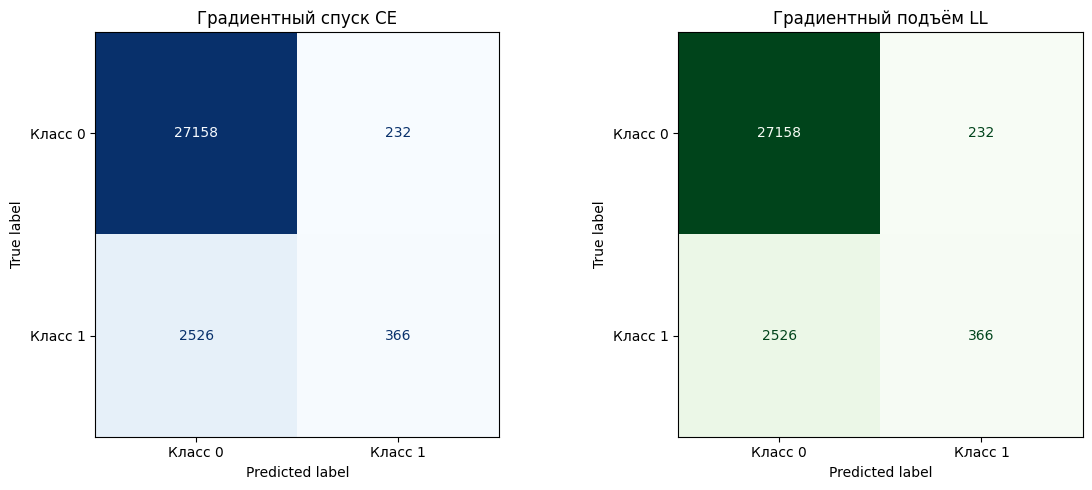

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_ce),
    display_labels=["Класс 0", "Класс 1"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Градиентный спуск CE")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_ll),
    display_labels=["Класс 0", "Класс 1"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Градиентный подъём LL")

plt.tight_layout()
plt.show()

## Сравнение изменения функции ошибки

Для метода градиентного спуска значение кросс-энтропии должно уменьшаться.

Для метода градиентного подъёма логарифмическое правдоподобие должно увеличиваться, то есть становиться ближе к нулю.

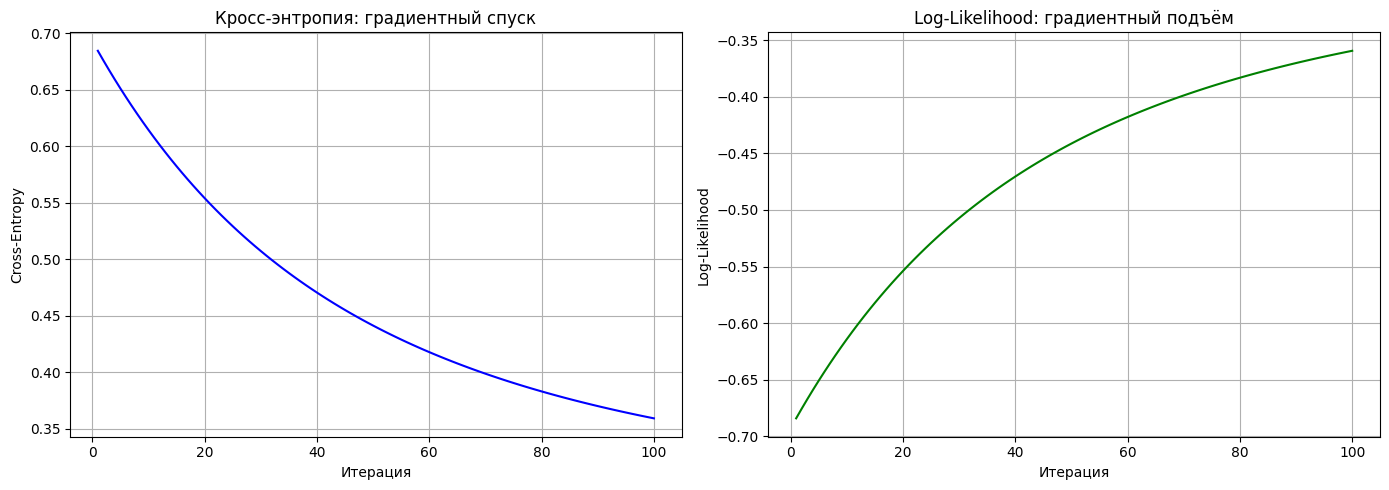

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    model_ce.steps_history,
    model_ce.loss_history,
    color="blue"
)
axes[0].set_title("Кросс-энтропия: градиентный спуск")
axes[0].set_xlabel("Итерация")
axes[0].set_ylabel("Cross-Entropy")
axes[0].grid(True)

axes[1].plot(
    model_ll.steps_history,
    model_ll.loss_history,
    color="green"
)
axes[1].set_title("Log-Likelihood: градиентный подъём")
axes[1].set_xlabel("Итерация")
axes[1].set_ylabel("Log-Likelihood")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Интерпретация коэффициентов

Коэффициенты модели показывают направление влияния признаков на вероятность класса `1`.

Положительный коэффициент увеличивает вероятность риска, отрицательный — уменьшает её.

In [ ]:
feature_names = ["intercept"] + list(X_train_df.columns)

coefficients = pd.DataFrame({
    "Признак": feature_names,
    "Коэффициент CE": model_ce.weights,
    "Коэффициент LL": model_ll.weights
})

coefficients["Абсолютное значение CE"] = (
    coefficients["Коэффициент CE"].abs()
)

display(
    coefficients
    .sort_values("Абсолютное значение CE", ascending=False)
    .head(20)
)

,Признак,Коэффициент CE,Коэффициент LL,Абсолютное значение CE
0,intercept,-1.2054,-1.2054,1.2054
9,variable_11,0.1484,0.1484,0.1484
15,variable_17,0.1218,0.1218,0.1218
21,variable_26,-0.0613,-0.0613,0.0613
11,variable_13,-0.0551,-0.0551,0.0551
12,variable_14,0.0538,0.0538,0.0538
22,variable_27,-0.0424,-0.0424,0.0424
17,variable_19,-0.0289,-0.0289,0.0289
30,variable_1_w200,0.0272,0.0272,0.0272
20,variable_25,0.0182,0.0182,0.0182


## Вывод

В работе были реализованы два способа обучения бинарной логистической регрессии:

1. градиентный спуск по функции бинарной кросс-энтропии;
2. градиентный подъём по логарифмическому правдоподобию.

Для сравнения использовались время обучения, accuracy, precision, recall и F1-score.

Из-за дисбаланса классов основное внимание следует уделять не только accuracy, но и F1-score, precision и recall для класса 1.

In [ ]:
best_model_row = metrics_table.loc[
    metrics_table["F1-score"].idxmax()
]

print(
    "Лучший метод по F1-score:",
    best_model_row["Метод"]
)

print(
    f"F1-score: {best_model_row['F1-score']:.4f}"
)

Лучший метод по F1-score: Градиентный спуск CE
F1-score: 0.2097


## Два способа обучения логистической регрессии

В работе используются два метода оптимизации параметров модели:

1. градиентный подъём по логарифмическому правдоподобию;
2. градиентный спуск по функции бинарной кросс-энтропии.

Оба метода изменяют коэффициенты логистической регрессии
и пытаются подобрать такие значения параметров, при которых
предсказания модели будут максимально близки к настоящим значениям
целевой переменной `target`.

Модель сначала вычисляет линейную комбинацию признаков:

$
z = Xw
$

Затем результат преобразуется в вероятность с помощью сигмоиды:

$
p = \frac{1}{1 + e^{-z}}
$

Значение `p` показывает вероятность того, что объект относится
к классу `1`.

## Метод градиентного подъёма

Градиентный подъём используется для максимизации логарифмического
правдоподобия модели.

Логарифмическое правдоподобие определяется формулой:

$
L(w) =
\frac{1}{n}
\sum_{i=1}^{n}
\left[
y_i \log(p_i)
+
(1-y_i)\log(1-p_i)
\right]
$

где:

- \(y_i\) — настоящее значение класса;
- \(p_i\) — предсказанная моделью вероятность класса `1`;
- \(n\) — количество объектов;
- \(w\) — коэффициенты модели.

Чем выше значение логарифмического правдоподобия,
тем лучше модель объясняет имеющиеся данные.

На каждой итерации вычисляется градиент:

$
\nabla L(w) =
\frac{1}{n}X^T(y-p)
$

После этого коэффициенты увеличиваются в направлении градиента:

$
w := w + \alpha \nabla L(w)
$

где \(\alpha\) — скорость обучения.

В программном коде это реализовано следующим образом:

```python
self.weights += learning_rate * gradient

## Сравнение методов

| Характеристика | Градиентный подъём | Градиентный спуск |
|---|---|---|
| Оптимизируемая функция | Log-Likelihood | Cross-Entropy |
| Направление оптимизации | Максимизация | Минимизация |
| Направление движения | По градиенту | Против градиента |
| Лучший результат | Максимальное значение функции | Минимальное значение функции |
| Используемая функция | \(L(w)\) | \(J(w)=-L(w)\) |
| Результат | Вероятности классов | Те же вероятности классов |

При одинаковых данных, скорости обучения и количестве итераций
оба метода должны получить близкие коэффициенты и одинаковые
предсказания.

В данной работе сравниваются не только итоговые значения метрик,
но и:

- время обучения;
- изменение функции ошибки;
- коэффициенты модели;
- accuracy;
- precision;
- recall;
- F1-score.

## Интерпретация полученных результатов

В результате эксперимента оба метода показали практически одинаковое
качество классификации.

Это объясняется тем, что градиентный подъём максимизирует
логарифмическое правдоподобие, а градиентный спуск минимизирует
его отрицательное значение — бинарную кросс-энтропию.

Время обучения может немного отличаться из-за особенностей вычислений
и загрузки процессора, но математический результат должен быть близким.

В данной задаче F1-score для класса `1` оказался значительно ниже,
чем accuracy. Это связано с дисбалансом классов: большая часть
договоров относится к классу `0`.

Поэтому высокая accuracy не означает, что модель хорошо находит
рисковые договоры. Для оценки обнаружения рисковых договоров
необходимо анализировать precision, recall и F1-score класса `1`.

## Вывод

В работе были реализованы два метода обучения бинарной логистической
регрессии.

Метод градиентного подъёма максимизирует логарифмическое
правдоподобие, а метод градиентного спуска минимизирует бинарную
кросс-энтропию.

Эти функции отличаются только знаком:

\[
CrossEntropy = -LogLikelihood
\]

Поэтому оба метода являются математически эквивалентными и при
одинаковых параметрах обучения должны приводить к близким результатам.

Различие между ними заключается в направлении изменения коэффициентов:

- градиентный подъём увеличивает значение логарифмического
  правдоподобия;
- градиентный спуск уменьшает значение кросс-энтропии.

Для итоговой оценки использовались accuracy, precision, recall,
F1-score и матрица ошибок.

Из-за дисбаланса классов наиболее важными метриками для данной задачи
являются recall и F1-score для класса `1`, так как класс `1`
соответствует рисковым страховым договорам.